# Fixed-pair percolation seed-set classification

This notebook asks whether Graph-A seed-set features distinguish successful from unsuccessful `ExpandWhenStuck` percolation runs on one fixed graph pair.

**Outcome.** `percolation_success = 1` when final unseeded accuracy is at least 0.90. There is one tie-break run per seed set, so this is a binary classification analysis rather than the grouped-binomial analysis used for SGM.

**Evaluation design.** Model diagnostics use 5-fold stratified cross-validation on the 400 uniformly random training sets. Final models are fitted on the selected training groups and evaluated once on the 200 held-out uniformly random test sets. The test set is not used for model selection or feature selection. All reported test metrics are therefore out of sample for this fixed pair.

In [1]:
import os
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

EXPERIMENT_DIR = Path.cwd().resolve()
if EXPERIMENT_DIR.name != 'fixed_pair_seed_set_classification':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'fixed_pair_seed_set_classification'

GRAPH_MODEL = 'chung_lu'  # 'sparse_er', 'paper_pa', or 'chung_lu'
PAIR_SEEDS = {
    'sparse_er': 4192889773,
    'paper_pa': 424242,
    'chung_lu': 3165569293,
}
PAIR_INDEX = 1
DATA_DIR = (
    EXPERIMENT_DIR / 'data' / 'percolation_fixed_pairs_2026-10-07' /
    GRAPH_MODEL / f'pair_{PAIR_INDEX}_seed_{PAIR_SEEDS[GRAPH_MODEL]}'
)
TRAIN_ON = 'all'  # 'all': random + constructed training sets; 'random': random only
INCLUDE_SIGNATURE_ROBUSTNESS = False
SUCCESS_THRESHOLD = 0.90
CV_FOLDS = 5
RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)


## 1. Load and verify the collection

The notebook checks the completion metadata, expected split sizes, unique seed sets, and the saved success label before performing any analysis.

In [2]:
import json

csv_path = DATA_DIR / f'{GRAPH_MODEL}_percolation_seed_sets.csv'
metadata_path = DATA_DIR / f'{GRAPH_MODEL}_percolation_seed_sets.metadata.json'

if not csv_path.exists() or not metadata_path.exists():
    raise FileNotFoundError(
        f'Collection not found in {DATA_DIR}. Change GRAPH_MODEL, PAIR_INDEX, '
        'PAIR_SEEDS, or DATA_DIR in the configuration cell.'
    )

data = pd.read_csv(csv_path)
metadata = json.loads(metadata_path.read_text(encoding='utf-8'))

if metadata.get('status') != 'complete':
    raise ValueError(f"Collection status is {metadata.get('status')!r}, not 'complete'.")
if len(data) != metadata.get('rows') or metadata.get('rows_completed') != len(data):
    raise ValueError('CSV row count does not match the completion metadata.')
if data['seed_vertices_graph1'].duplicated().any():
    raise ValueError('The collection contains duplicate seed sets.')

expected_success = data['final_unseeded_accuracy'].ge(SUCCESS_THRESHOLD)
if not expected_success.equals(data['percolation_success'].astype(bool)):
    raise ValueError('Saved percolation_success does not match the configured threshold.')

data['percolation_success'] = data['percolation_success'].astype(int)

core_features = list(metadata['feature_columns'])
robustness_features = [
    feature for feature in metadata.get('robustness_feature_columns', [])
    if feature in data.columns
]
features = core_features + (robustness_features if INCLUDE_SIGNATURE_ROBUSTNESS else [])
missing_features = [feature for feature in features if feature not in data]
if missing_features:
    raise ValueError(f'Missing feature columns: {missing_features}')

collection_summary = pd.Series({
    'graph model': GRAPH_MODEL,
    'graph-pair seed': metadata['graph_pair_seed'],
    'vertices': metadata['config']['vertex_count'],
    'seed budget k': metadata['config']['n_seeds'],
    'rows': len(data),
    'success threshold': metadata['success_threshold'],
    'percolation threshold r': metadata['percolation_threshold'],
    'runs per set': metadata['runs_per_seed_set'],
    'collection minutes': metadata.get('collection_minutes'),
    'predictor count': len(features),
})
display(collection_summary.to_frame('value'))


,value
graph model,chung_lu
graph-pair seed,3165569293
vertices,600
seed budget k,5
rows,1000
success threshold,0.9
percolation threshold r,2
runs per set,1
collection minutes,6.97
predictor count,9


## 2. Label and accuracy distribution

The table separates the representative random sets from the constructed degree-weighted and degree-controlled sets. The held-out test rows are uniformly random seed sets.

,data_split,sampling_strategy,sets,successes,success_fraction,mean_accuracy,median_accuracy,mean_matched_fraction,mean_precision
0,test,random,200,88,0.440,0.494,0.328,0.935,0.507
1,train,degree_controlled,200,79,0.395,0.492,0.320,0.935,0.507
2,train,degree_weighted,200,117,0.585,0.659,0.944,0.953,0.674
3,train,random,400,186,0.465,0.539,0.785,0.940,0.553


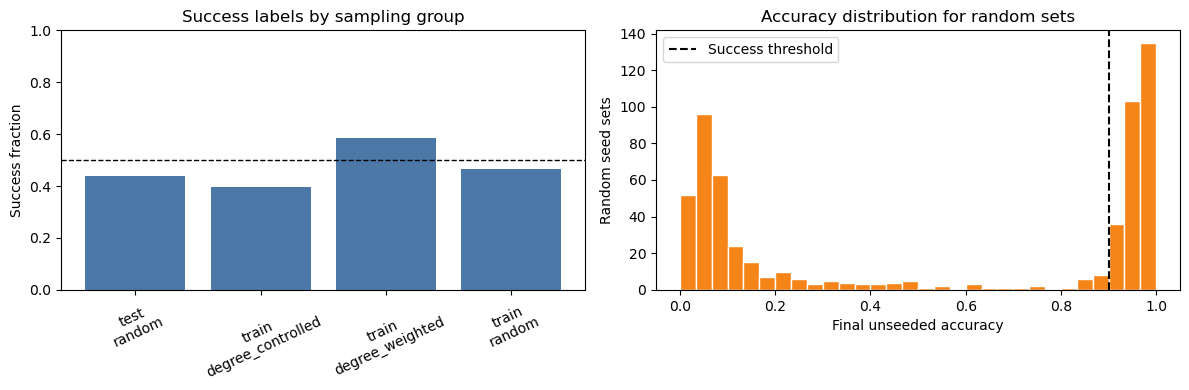

In [3]:
group_summary = (
    data.groupby(['data_split', 'sampling_strategy'], observed=True)
    .agg(
        sets=('candidate_id', 'size'),
        successes=('percolation_success', 'sum'),
        success_fraction=('percolation_success', 'mean'),
        mean_accuracy=('final_unseeded_accuracy', 'mean'),
        median_accuracy=('final_unseeded_accuracy', 'median'),
        mean_matched_fraction=('percolation_matched_unseeded_fraction', 'mean'),
        mean_precision=('percolation_unseeded_precision', 'mean'),
    )
    .reset_index()
)
display(group_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [f'{row.data_split}\n{row.sampling_strategy}' for row in group_summary.itertuples()]
axes[0].bar(labels, group_summary['success_fraction'], color='#4C78A8')
axes[0].axhline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Success fraction')
axes[0].set_title('Success labels by sampling group')
axes[0].tick_params(axis='x', rotation=25)

random_sets = data[data['sampling_strategy'].eq('random')]
axes[1].hist(
    random_sets['final_unseeded_accuracy'], bins=np.linspace(0, 1, 31),
    color='#F58518', edgecolor='white'
)
axes[1].axvline(SUCCESS_THRESHOLD, color='black', linestyle='--', label='Success threshold')
axes[1].set_xlabel('Final unseeded accuracy')
axes[1].set_ylabel('Random seed sets')
axes[1].set_title('Accuracy distribution for random sets')
axes[1].legend()
plt.tight_layout()
plt.show()


## 3. Predictor panel and data splits

The nine primary predictors are exactly the Graph-A seed-set features used in the SGM analysis. Radius-2 and radius-4 signature uniqueness can be added as robustness predictors with `INCLUDE_SIGNATURE_ROBUSTNESS = True`; they are excluded by default to keep the primary panel fixed.

In [4]:
feature_labels = {
    'seed_nonseed_degree_mean': 'Seed–nonseed degree',
    'seed_harmonic_mean': 'Seed harmonic mean',
    'nonseed_covered_fraction': 'Nonseed coverage',
    'nonseed_witness_overlap_fraction': 'Witness overlap',
    'nonseed_witness_pair_mass_mean': 'Witness-pair mass',
    'nonseed_nearest_seed_distance_mean': 'Nearest-seed distance',
    'nonseed_three_hop_seed_count_mean': 'Seeds within 3 hops',
    'nonseed_distance_signature_unique_fraction_r3': 'Signature uniqueness r=3',
    'seed_nonseed_neighborhood_jaccard_mean': 'Seed-neighborhood Jaccard',
    'nonseed_distance_signature_unique_fraction_r2': 'Signature uniqueness r=2',
    'nonseed_distance_signature_unique_fraction_r4': 'Signature uniqueness r=4',
}

train = data[data['data_split'].eq('train')].copy()
random_train = train[train['sampling_strategy'].eq('random')].copy()
test = data[data['data_split'].eq('test')].copy()
fit_train = train if TRAIN_ON == 'all' else random_train

if not test['sampling_strategy'].eq('random').all():
    raise ValueError('The held-out test set must contain only uniformly random sets.')
if test['percolation_success'].nunique() < 2:
    raise ValueError('The test set contains only one class; ROC-AUC is undefined.')

split_summary = pd.DataFrame({
    'sets': [len(random_train), len(fit_train), len(test)],
    'success_fraction': [
        random_train['percolation_success'].mean(),
        fit_train['percolation_success'].mean(),
        test['percolation_success'].mean(),
    ],
}, index=['Random training (CV)', f'Final fitting ({TRAIN_ON})', 'Held-out random test'])
display(split_summary.round(3))
display(pd.DataFrame({
    'feature': features,
    'display name': [feature_labels.get(feature, feature) for feature in features],
}))


,sets,success_fraction
Random training (CV),400,0.465
Final fitting (all),800,0.478
Held-out random test,200,0.440


,feature,display name
0,seed_nonseed_degree_mean,Seed–nonseed degree
1,seed_harmonic_mean,Seed harmonic mean
2,nonseed_covered_fraction,Nonseed coverage
3,nonseed_witness_overlap_fraction,Witness overlap
4,nonseed_witness_pair_mass_mean,Witness-pair mass
5,nonseed_nearest_seed_distance_mean,Nearest-seed distance
6,nonseed_three_hop_seed_count_mean,Seeds within 3 hops
7,nonseed_distance_signature_unique_fraction_r3,Signature uniqueness r=3
8,seed_nonseed_neighborhood_jaccard_mean,Seed-neighborhood Jaccard


## 4. Classification models

- **No-feature baseline:** predicts the training class frequency.
- **Degree-only logistic regression:** tests the established degree baseline.
- **Full logistic regression:** estimates a linear relationship using standardized predictors.
- **Random forest:** captures nonlinear effects and interactions.

The cross-validation table below is a training diagnostic computed only from uniformly random training sets. It is separate from the final held-out test table.

In [5]:
degree_feature = ['seed_nonseed_degree_mean']
model_specs = {
    'No-feature baseline': (
        features,
        Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', DummyClassifier(strategy='prior')),
        ]),
    ),
    'Degree logistic': (
        degree_feature,
        Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE)),
        ]),
    ),
    'Full logistic': (
        features,
        Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE)),
        ]),
    ),
    'Random forest': (
        features,
        Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', RandomForestClassifier(
                n_estimators=500,
                min_samples_leaf=5,
                max_features='sqrt',
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
    ),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'ROC-AUC': 'roc_auc',
    'Average precision': 'average_precision',
    'Accuracy': 'accuracy',
    'Balanced accuracy': 'balanced_accuracy',
    'Brier score': 'neg_brier_score',
}
cv_rows = []
for name, (model_features, estimator) in model_specs.items():
    scores = cross_validate(
        estimator,
        random_train[model_features],
        random_train['percolation_success'],
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score='raise',
    )
    row = {'Model': name}
    for metric in scoring:
        values = scores[f'test_{metric}']
        if metric == 'Brier score':
            values = -values
        row[f'{metric} mean'] = values.mean()
        row[f'{metric} SD'] = values.std(ddof=1)
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index('Model')
print('Training evaluation: 5-fold CV on uniformly random training sets')
display(cv_results.round(3))


Training evaluation: 5-fold CV on uniformly random training sets


,ROC-AUC mean,ROC-AUC SD,Average precision mean,Average precision SD,Accuracy mean,Accuracy SD,Balanced accuracy mean,Balanced accuracy SD,Brier score mean,Brier score SD
Model,,,,,,,,,,
No-feature baseline,0.500,0.000,0.465,0.006,0.535,0.006,0.500,0.000,0.249,0.000
Degree logistic,0.649,0.064,0.626,0.073,0.620,0.050,0.605,0.053,0.235,0.012
Full logistic,0.759,0.048,0.717,0.073,0.670,0.047,0.666,0.049,0.204,0.021
Random forest,0.703,0.046,0.657,0.039,0.630,0.036,0.630,0.035,0.221,0.017


## 5. Held-out random-test evaluation

Each model is now fitted once using the configured training rows and evaluated on the untouched 200-set random test sample. ROC-AUC measures discrimination independent of a probability threshold; 0.5 is chance and 1.0 is perfect ordering.

Testing evaluation: held-out uniformly random seed sets


,ROC-AUC,Average precision,Accuracy,Balanced accuracy,Brier score,Mean predicted p,Observed success
Model,,,,,,,
No-feature baseline,0.500,0.440,0.560,0.500,0.248,0.478,0.44
Degree logistic,0.668,0.580,0.605,0.565,0.234,0.433,0.44
Full logistic,0.761,0.729,0.720,0.704,0.196,0.409,0.44
Random forest,0.752,0.690,0.675,0.670,0.201,0.444,0.44


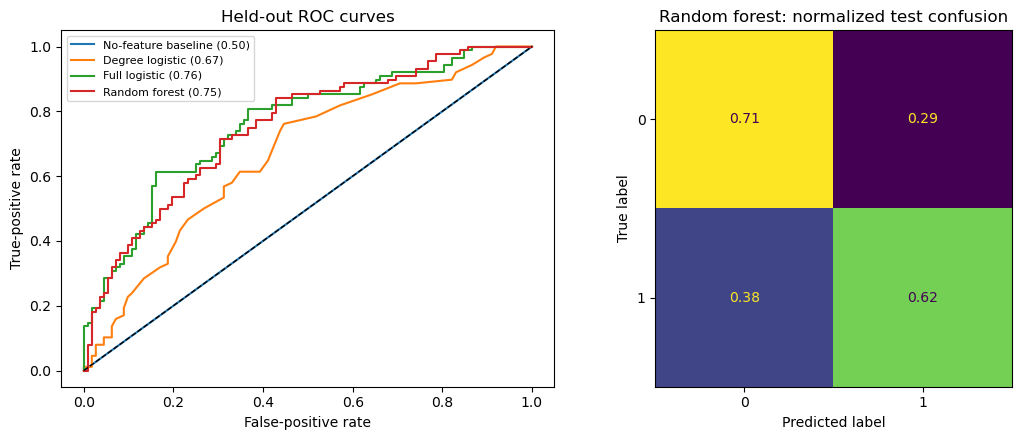

In [6]:
fitted_models = {}
test_probabilities = {}
test_predictions = {}
test_rows = []

y_test = test['percolation_success'].to_numpy()
for name, (model_features, estimator) in model_specs.items():
    fitted = clone(estimator).fit(
        fit_train[model_features], fit_train['percolation_success']
    )
    probability = fitted.predict_proba(test[model_features])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    fitted_models[name] = fitted
    test_probabilities[name] = probability
    test_predictions[name] = prediction
    test_rows.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, probability),
        'Average precision': average_precision_score(y_test, probability),
        'Accuracy': accuracy_score(y_test, prediction),
        'Balanced accuracy': balanced_accuracy_score(y_test, prediction),
        'Brier score': brier_score_loss(y_test, probability),
        'Mean predicted p': probability.mean(),
        'Observed success': y_test.mean(),
    })

test_results = pd.DataFrame(test_rows).set_index('Model')
print('Testing evaluation: held-out uniformly random seed sets')
display(test_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, probability in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    axes[0].plot(fpr, tpr, label=f"{name} ({test_results.loc[name, 'ROC-AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate', title='Held-out ROC curves')
axes[0].legend(fontsize=8)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions['Random forest'],
    normalize='true',
    values_format='.2f',
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title('Random forest: normalized test confusion')
plt.tight_layout()
plt.show()


## 6. Held-out feature importance

Permutation importance measures how much test ROC-AUC falls when one predictor is shuffled. It is evaluated on the held-out random sets, so it answers which collected features the fitted model actually needs for out-of-sample ranking. Correlated predictors can share importance, so low importance does not prove that a feature is scientifically irrelevant.

,Model,Feature,Display feature,Mean ROC-AUC decrease,SD
3,Full logistic,nonseed_witness_overlap_fraction,Witness overlap,0.183,0.032
1,Full logistic,seed_harmonic_mean,Seed harmonic mean,0.089,0.029
5,Full logistic,nonseed_nearest_seed_distance_mean,Nearest-seed distance,0.012,0.008
2,Full logistic,nonseed_covered_fraction,Nonseed coverage,0.003,0.006
7,Full logistic,nonseed_distance_signature_unique_fraction_r3,Signature uniqueness r=3,0.002,0.002
0,Full logistic,seed_nonseed_degree_mean,Seed–nonseed degree,0.002,0.005
4,Full logistic,nonseed_witness_pair_mass_mean,Witness-pair mass,0.002,0.004
8,Full logistic,seed_nonseed_neighborhood_jaccard_mean,Seed-neighborhood Jaccard,0.001,0.004
6,Full logistic,nonseed_three_hop_seed_count_mean,Seeds within 3 hops,0.000,0.001
12,Random forest,nonseed_witness_overlap_fraction,Witness overlap,0.029,0.013


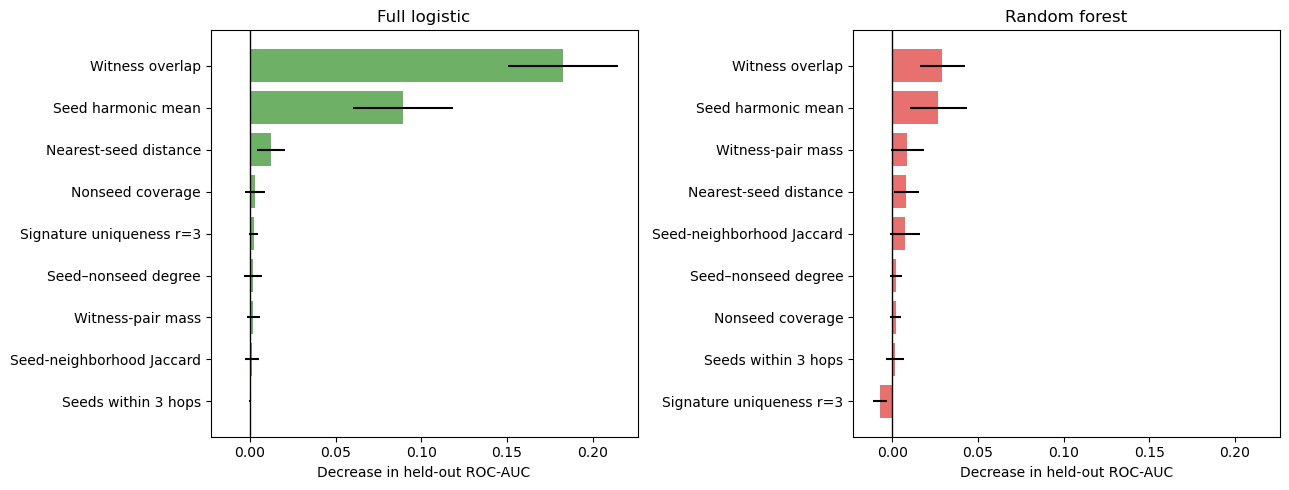

In [7]:
importance_frames = []
for name in ('Full logistic', 'Random forest'):
    model_features = model_specs[name][0]
    result = permutation_importance(
        fitted_models[name],
        test[model_features],
        y_test,
        scoring='roc_auc',
        n_repeats=30,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    importance_frames.append(pd.DataFrame({
        'Model': name,
        'Feature': model_features,
        'Display feature': [feature_labels.get(feature, feature) for feature in model_features],
        'Mean ROC-AUC decrease': result.importances_mean,
        'SD': result.importances_std,
    }))

permutation_table = pd.concat(importance_frames, ignore_index=True)
display(
    permutation_table.sort_values(
        ['Model', 'Mean ROC-AUC decrease'], ascending=[True, False]
    ).round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, name in zip(axes, ('Full logistic', 'Random forest')):
    plot_data = (
        permutation_table[permutation_table['Model'].eq(name)]
        .sort_values('Mean ROC-AUC decrease')
    )
    ax.barh(
        plot_data['Display feature'],
        plot_data['Mean ROC-AUC decrease'],
        xerr=plot_data['SD'],
        color='#54A24B' if name == 'Full logistic' else '#E45756',
        alpha=0.85,
    )
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('Decrease in held-out ROC-AUC')
plt.tight_layout()
plt.show()


## 7. Model-specific direction and importance

Standardized logistic coefficients show the fitted direction of a linear association. Random-forest impurity importance shows how frequently and effectively a feature splits training observations. Use these as supporting descriptions; held-out permutation importance above is the primary importance result.

In [8]:
logistic_coefficients = pd.DataFrame({
    'Feature': features,
    'Display feature': [feature_labels.get(feature, feature) for feature in features],
    'Standardized coefficient': fitted_models['Full logistic'].named_steps['model'].coef_[0],
}).sort_values('Standardized coefficient', key=np.abs, ascending=False)

forest_importance = pd.DataFrame({
    'Feature': features,
    'Display feature': [feature_labels.get(feature, feature) for feature in features],
    'Forest impurity importance': fitted_models['Random forest'].named_steps['model'].feature_importances_,
}).sort_values('Forest impurity importance', ascending=False)

print('Full logistic regression')
display(logistic_coefficients.round(3))
print('Random forest')
display(forest_importance.round(3))


Full logistic regression


,Feature,Display feature,Standardized coefficient
3,nonseed_witness_overlap_fraction,Witness overlap,1.401
1,seed_harmonic_mean,Seed harmonic mean,1.376
2,nonseed_covered_fraction,Nonseed coverage,-0.501
0,seed_nonseed_degree_mean,Seed–nonseed degree,-0.500
4,nonseed_witness_pair_mass_mean,Witness-pair mass,-0.451
5,nonseed_nearest_seed_distance_mean,Nearest-seed distance,-0.346
8,seed_nonseed_neighborhood_jaccard_mean,Seed-neighborhood Jaccard,-0.168
7,nonseed_distance_signature_unique_fraction_r3,Signature uniqueness r=3,0.074
6,nonseed_three_hop_seed_count_mean,Seeds within 3 hops,-0.012


Random forest


,Feature,Display feature,Forest impurity importance
3,nonseed_witness_overlap_fraction,Witness overlap,0.193
8,seed_nonseed_neighborhood_jaccard_mean,Seed-neighborhood Jaccard,0.176
4,nonseed_witness_pair_mass_mean,Witness-pair mass,0.155
1,seed_harmonic_mean,Seed harmonic mean,0.147
6,nonseed_three_hop_seed_count_mean,Seeds within 3 hops,0.102
5,nonseed_nearest_seed_distance_mean,Nearest-seed distance,0.079
7,nonseed_distance_signature_unique_fraction_r3,Signature uniqueness r=3,0.057
0,seed_nonseed_degree_mean,Seed–nonseed degree,0.049
2,nonseed_covered_fraction,Nonseed coverage,0.043


## 8. Compact interpretation

This cell identifies the strongest held-out model and features without replacing inspection of the full tables and plots.

In [9]:
nonbaseline = test_results.drop(index='No-feature baseline')
best_model = nonbaseline['ROC-AUC'].idxmax()
best_auc = nonbaseline.loc[best_model, 'ROC-AUC']
rf_top = (
    permutation_table[permutation_table['Model'].eq('Random forest')]
    .sort_values('Mean ROC-AUC decrease', ascending=False)
    .head(3)
)

print(f'Graph model: {GRAPH_MODEL}; fixed pair seed: {metadata["graph_pair_seed"]}')
print(f'Random training success: {random_train.percolation_success.mean():.1%}')
print(f'Held-out random-test success: {test.percolation_success.mean():.1%}')
print(f'Best held-out discriminator: {best_model}, ROC-AUC = {best_auc:.3f}')
print('Top random-forest permutation features:')
for _, row in rf_top.iterrows():
    print(
        f"  {row['Display feature']}: ROC-AUC decrease "
        f"{row['Mean ROC-AUC decrease']:.3f} ± {row['SD']:.3f}"
    )


Graph model: chung_lu; fixed pair seed: 3165569293
Random training success: 46.5%
Held-out random-test success: 44.0%
Best held-out discriminator: Full logistic, ROC-AUC = 0.761
Top random-forest permutation features:
  Witness overlap: ROC-AUC decrease 0.029 ± 0.013
  Seed harmonic mean: ROC-AUC decrease 0.027 ± 0.017
  Witness-pair mass: ROC-AUC decrease 0.009 ± 0.010


## Interpretation limits

- This notebook describes one fixed graph pair. Repeat it independently on additional pairs before claiming that a ranking transfers across graph draws.
- Each seed set has one percolation run, so the label combines seed-set quality with one realization of tie breaking.
- Constructed training sets broaden the feature range. The held-out test set remains uniformly random, which is the relevant reference distribution for the reported test metrics.
- Feature importance is predictive rather than causal. Degree-controlled contrasts provide a separate descriptive check of effects beyond seed-to-nonseed degree.